<a href="https://colab.research.google.com/github/PrasadJagdale1939/Google_Colab_Practice/blob/main/Air_Pollution_and_Weather_Patterns.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
## importing the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns",100)

In [ ]:
##Loading data set
air =pd.read_csv("/content/air_quality_daily.csv")
weather =pd.read_csv("/content/weather_daily.csv")
cities =pd.read_csv("/content/cities.csv")

print(f"Air Quality Shape : {air.shape}")
print(f"Weather Shape : {weather.shape}")
print(f"Cities Shape : {cities.shape}")

Air Quality Shape : (77250, 19)
Weather Shape : (124600, 14)
Cities Shape : (50, 6)


In [ ]:
display(air.head())
display(weather.head())
display(cities.head())

,date,city,pm2_5_mean,pm2_5_max,pm10_mean,pm10_max,no2_mean,so2_mean,o3_8h_max,co_8h_max,dust_mean,aod_mean,us_aqi_max,hours_available,india_aqi,india_aqi_category,dominant_pollutant,india_aqi_pm,india_aqi_pm_category
0,2022-08-05,Agartala,14.09,19.1,20.50,27.6,20.63,2.32,72.00,204.75,0.0,0.18,61.0,24,72,Satisfactory,O3,23,Good
1,2022-08-06,Agartala,12.12,19.3,17.44,27.7,23.11,1.10,48.00,208.00,0.0,0.16,60.0,24,48,Good,O3,20,Good
2,2022-08-07,Agartala,11.85,19.0,17.18,27.6,22.27,1.18,75.00,238.38,0.0,0.15,56.0,24,75,Satisfactory,O3,20,Good
3,2022-08-08,Agartala,9.28,13.5,13.47,19.5,16.25,1.10,65.25,241.38,0.0,0.12,57.0,24,65,Satisfactory,O3,15,Good
4,2022-08-09,Agartala,6.33,7.4,9.25,10.8,11.51,1.28,69.38,181.88,0.0,0.10,51.0,24,69,Satisfactory,O3,11,Good


,date,city,temperature_2m_max,temperature_2m_min,temperature_2m_mean,apparent_temperature_max,precipitation_sum,precipitation_hours,relative_humidity_2m_mean,wind_speed_10m_max,wind_direction_10m_dominant,shortwave_radiation_sum,et0_fao_evapotranspiration,weather_code
0,2020-01-01,Agartala,26.2,16.2,20.5,28.3,0.3,3.0,79,11.5,60,11.62,2.29,51
1,2020-01-02,Agartala,26.5,15.0,20.2,28.8,0.0,0.0,86,8.0,30,11.70,2.25,3
2,2020-01-03,Agartala,20.2,15.7,18.0,21.4,18.5,16.0,90,17.1,27,5.77,1.14,63
3,2020-01-04,Agartala,21.8,14.7,17.9,22.7,0.6,2.0,86,9.4,221,8.38,1.62,51
4,2020-01-05,Agartala,21.8,13.6,17.0,22.1,0.0,0.0,85,8.7,358,9.72,1.82,3


,city,state,region,latitude,longitude,elevation_m
0,Delhi,Delhi,North,28.6139,77.2090,214.0
1,Mumbai,Maharashtra,West,19.0760,72.8777,6.0
2,Kolkata,West Bengal,East,22.5726,88.3639,12.0
3,Chennai,Tamil Nadu,South,13.0827,80.2707,12.0
4,Bengaluru,Karnataka,South,12.9716,77.5946,910.0


In [ ]:
print(f"Air Columns : {air.columns.tolist()}")
print(f"Weather Columns : {weather.columns.tolist()}")
print(f"Cities Columns : {cities.columns.tolist()}")

Air Columns : ['date', 'city', 'pm2_5_mean', 'pm2_5_max', 'pm10_mean', 'pm10_max', 'no2_mean', 'so2_mean', 'o3_8h_max', 'co_8h_max', 'dust_mean', 'aod_mean', 'us_aqi_max', 'hours_available', 'india_aqi', 'india_aqi_category', 'dominant_pollutant', 'india_aqi_pm', 'india_aqi_pm_category']
Weather Columns : ['date', 'city', 'temperature_2m_max', 'temperature_2m_min', 'temperature_2m_mean', 'apparent_temperature_max', 'precipitation_sum', 'precipitation_hours', 'relative_humidity_2m_mean', 'wind_speed_10m_max', 'wind_direction_10m_dominant', 'shortwave_radiation_sum', 'et0_fao_evapotranspiration', 'weather_code']
Cities Columns : ['city', 'state', 'region', 'latitude', 'longitude', 'elevation_m']


In [ ]:
print("\nAir Quality Data Types: ")
air.info()
print("\nWeather Data Types: ")
weather.info()


Air Quality Data Types: 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77250 entries, 0 to 77249
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   77250 non-null  object 
 1   city                   77250 non-null  object 
 2   pm2_5_mean             77250 non-null  float64
 3   pm2_5_max              77250 non-null  float64
 4   pm10_mean              77250 non-null  float64
 5   pm10_max               77250 non-null  float64
 6   no2_mean               77250 non-null  float64
 7   so2_mean               77250 non-null  float64
 8   o3_8h_max              77250 non-null  float64
 9   co_8h_max              77250 non-null  float64
 10  dust_mean              77250 non-null  float64
 11  aod_mean               77250 non-null  float64
 12  us_aqi_max             77250 non-null  float64
 13  hours_available        77250 non-null  int64  
 14  india_aqi              77250

In [ ]:
def standardize_columns(df):
  df = df.copy()
  df.columns =(
      df.columns.astype(str).str.strip().str.lower().str.replace(r"[^a-z0-9]+","_",regex=True).str.strip("_")

  )
  return df

air = standardize_columns(air)
weather = standardize_columns(weather)
cities = standardize_columns(cities)

def find_column(df, candidates, description):
  for col in candidates:
    if col in df.columns:
      return col
  raise ValueError(
      f"Could not identify {description}. Available columns: {df.columns.tolist()}."
      f"Please add the correct column name to candidates."
  )

air_date = find_column(air, ["date","datetime","timestamp","time"],"air-quality date")
weather_date = find_column(weather, ["date","datetime","timestamp","time"],"weather date")
air_city = find_column(air, ["city","location","city_name"],"air-quality city")
weather_city = find_column(weather, ["city","location","city_name"],"weather city")


air[air_date] = pd.to_datetime(air[air_date],errors="coerce")
weather[weather_date] = pd.to_datetime(weather[weather_date],errors="coerce")


air = air.rename(columns={air_date: "date", air_city:"city"})
weather = weather.rename(columns={weather_date:"date",weather_city:"city"})


air["city"]= air["city"].astype(str).str.strip().str.lower()
weather["city"]= weather["city"].astype(str).str.strip().str.lower()


print(f"Air date range : {air["date"].min()} to {air["date"].max()}" )
print(f"Weather date range : {weather["date"].min()} to {weather["date"].max()}" )
print(f"Air Columns : {air.columns.tolist()}")
print(f"Weather Columns : {weather.columns.tolist()}")



Air date range : 2022-08-05 00:00:00 to 2026-10-27 00:00:00
Weather date range : 2020-01-01 00:00:00 to 2026-10-27 00:00:00
Air Columns : ['date', 'city', 'pm2_5_mean', 'pm2_5_max', 'pm10_mean', 'pm10_max', 'no2_mean', 'so2_mean', 'o3_8h_max', 'co_8h_max', 'dust_mean', 'aod_mean', 'us_aqi_max', 'hours_available', 'india_aqi', 'india_aqi_category', 'dominant_pollutant', 'india_aqi_pm', 'india_aqi_pm_category']
Weather Columns : ['date', 'city', 'temperature_2m_max', 'temperature_2m_min', 'temperature_2m_mean', 'apparent_temperature_max', 'precipitation_sum', 'precipitation_hours', 'relative_humidity_2m_mean', 'wind_speed_10m_max', 'wind_direction_10m_dominant', 'shortwave_radiation_sum', 'et0_fao_evapotranspiration', 'weather_code']


In [ ]:
print(f"Missing Values in Air Quality : ")
display(air.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

print(f"Missing Values in Weather : ")
display(weather.isna().sum().sort_values(ascending=False).to_frame("missing_count"))


print(f"Duplicate city-date rows in Air: {air.duplicated(subset=["city","date"]).sum()}")
print(f"Duplicate city-date rows in Weather: {weather.duplicated(subset=["city","date"]).sum()}")

Missing Values in Air Quality : 


,missing_count
date,0
city,0
pm2_5_mean,0
pm2_5_max,0
pm10_mean,0
pm10_max,0
no2_mean,0
so2_mean,0
o3_8h_max,0
co_8h_max,0


Missing Values in Weather : 


,missing_count
date,0
city,0
temperature_2m_max,0
temperature_2m_min,0
temperature_2m_mean,0
apparent_temperature_max,0
precipitation_sum,0
precipitation_hours,0
relative_humidity_2m_mean,0
wind_speed_10m_max,0


Duplicate city-date rows in Air: 0
Duplicate city-date rows in Weather: 0


In [ ]:
def collapse_city_date(df):
  df = df.dropna(subset=["city","date"]).copy()
  numeric_cols = df.select_dtypes(include="number").columns.tolist()
  other_cols = [c for c in df.columns if c not in numeric_cols +["city","date"]]
  agg ={c:"mean" for c in numeric_cols}
  agg.update({c:"first" for c in other_cols})
  return df.groupby(["city","date"], as_index=False).agg(agg)

air_clean = collapse_city_date(air)
weather_clean = collapse_city_date(weather)

df = air_clean.merge(
    weather_clean, on=["city","date"], how="inner" , suffixes=("_air","_weather")
)

print(f"Air Rows After Cleaning : {len(air_clean)}")
print(f"Weather Rows After Cleaning : {len(weather_clean)}")
print(f"Matched combined rows  : {len(df)}")
display(df.head())

Air Rows After Cleaning : 77250
Weather Rows After Cleaning : 124600
Matched combined rows  : 77250


,city,date,pm2_5_mean,pm2_5_max,pm10_mean,pm10_max,no2_mean,so2_mean,o3_8h_max,co_8h_max,dust_mean,aod_mean,us_aqi_max,hours_available,india_aqi,india_aqi_pm,india_aqi_category,dominant_pollutant,india_aqi_pm_category,temperature_2m_max,temperature_2m_min,temperature_2m_mean,apparent_temperature_max,precipitation_sum,precipitation_hours,relative_humidity_2m_mean,wind_speed_10m_max,wind_direction_10m_dominant,shortwave_radiation_sum,et0_fao_evapotranspiration,weather_code
0,agartala,2022-08-05,14.09,19.1,20.50,27.6,20.63,2.32,72.00,204.75,0.0,0.18,61.0,24.0,72.0,23.0,Satisfactory,O3,Good,33.3,25.7,29.0,41.7,12.1,7.0,83.0,10.5,150.0,21.19,4.63,63.0
1,agartala,2022-08-06,12.12,19.3,17.44,27.7,23.11,1.10,48.00,208.00,0.0,0.16,60.0,24.0,48.0,20.0,Good,O3,Good,32.4,25.4,28.1,40.8,8.7,17.0,86.0,8.8,125.0,17.90,3.89,63.0
2,agartala,2022-08-07,11.85,19.0,17.18,27.6,22.27,1.18,75.00,238.38,0.0,0.15,56.0,24.0,75.0,20.0,Satisfactory,O3,Good,33.8,25.7,29.5,42.2,0.3,2.0,79.0,11.5,160.0,23.91,5.31,51.0
3,agartala,2022-08-08,9.28,13.5,13.47,19.5,16.25,1.10,65.25,241.38,0.0,0.12,57.0,24.0,65.0,15.0,Satisfactory,O3,Good,33.1,25.5,28.4,40.3,12.8,18.0,84.0,17.4,123.0,20.32,4.55,63.0
4,agartala,2022-08-09,6.33,7.4,9.25,10.8,11.51,1.28,69.38,181.88,0.0,0.10,51.0,24.0,69.0,11.0,Satisfactory,O3,Good,32.9,25.5,28.3,38.4,2.4,6.0,79.0,19.4,144.0,22.10,5.08,61.0


In [ ]:
def find_optional_column(df, candidates):
    for col in candidates:
        if col in df.columns:
          return col
    return None

pm25_col= find_optional_column(df, ["pm2_5", "pm25", "pm2.5", "pm2_5_mean", "pm25_mean"])
pm10_col= find_optional_column(df, ["pm10", "pm10_mean"])
no2_col= find_optional_column(df, ["no2", "nitrogen_dioxide", "no2_mean"])
o3_col = find_optional_column(df, ["o3", "ozone", "o3_mean"])
temp_col =find_optional_column(df, ["temperature_2m_mean", "temperature_mean", "temperature_2m_max", "temperature", "temp"])
humidity_col = find_optional_column(df, ["relative_humidity_2m_mean", "humidity_mean", "humidity", "relative_humidity"])
wind_col =find_optional_column(df, ["wind_speed_10m_mean", "wind_speed_mean", "wind_speed", "windspeed"])
rain_col= find_optional_column(df, ["precipitation_sum", "rainfall", "rain", "precipitation"])

print(f"PM2.5: {pm25_col}")
print(f"PM10: {pm10_col}")
print(f"NO2: {no2_col}")
print(f"O3: {o3_col}")
print(f"Temperature: {temp_col}")
print(f"Humidity: {humidity_col}")
print(f"Wind speed: {wind_col}")
print(f"Rainfall/precipitation: {rain_col}")
print(f"\nAll combined columns:")
print(df.columns.tolist())

PM2.5: pm2_5_mean
PM10: pm10_mean
NO2: no2_mean
O3: None
Temperature: temperature_2m_mean
Humidity: relative_humidity_2m_mean
Wind speed: None
Rainfall/precipitation: precipitation_sum

All combined columns:
['city', 'date', 'pm2_5_mean', 'pm2_5_max', 'pm10_mean', 'pm10_max', 'no2_mean', 'so2_mean', 'o3_8h_max', 'co_8h_max', 'dust_mean', 'aod_mean', 'us_aqi_max', 'hours_available', 'india_aqi', 'india_aqi_pm', 'india_aqi_category', 'dominant_pollutant', 'india_aqi_pm_category', 'temperature_2m_max', 'temperature_2m_min', 'temperature_2m_mean', 'apparent_temperature_max', 'precipitation_sum', 'precipitation_hours', 'relative_humidity_2m_mean', 'wind_speed_10m_max', 'wind_direction_10m_dominant', 'shortwave_radiation_sum', 'et0_fao_evapotranspiration', 'weather_code']


In [ ]:
candidate_measurements= [pm25_col,pm10_col,no2_col,o3_col, temp_col,humidity_col,wind_col,rain_col]
measurement_cols = [ c for c in candidate_measurements if c is not None]

for col in measurement_cols:
  df[col] = pd.to_numeric(df[col],errors="coerce")

for col in [pm25_col, pm10_col, no2_col, o3_col, wind_col,rain_col]:
  if col is not None:
    df.loc[df[col]<0,col]=np.nan

if humidity_col is not None:
  df.loc[~df[humidity_col].between(0,100),humidity_col]=np.nan

print("Missing values after Basic Cleaning : ")
display(df[measurement_cols].isna().sum().to_frame("missing_count"))

Missing values after Basic Cleaning : 


,missing_count
pm2_5_mean,0
pm10_mean,0
no2_mean,0
temperature_2m_mean,0
relative_humidity_2m_mean,0
precipitation_sum,0


In [ ]:
df["month"]=df["date"].dt.month
df["year"]=df["date"].dt.year

def get_season(month):
  if month in [12,1,2]:
    return "Winter"
  elif month in [3,4,5]:
    return "Summer"
  elif month in [6,7,8,9]:
    return "Monsoon"
  return "Post-monsoon"

df["season"]=df["month"].apply(get_season)
display(df[["date","city","month","season"]].head())

,date,city,month,season
0,2022-08-05,agartala,8,Monsoon
1,2022-08-06,agartala,8,Monsoon
2,2022-08-07,agartala,8,Monsoon
3,2022-08-08,agartala,8,Monsoon
4,2022-08-09,agartala,8,Monsoon


,count,mean,std,min,25%,50%,75%,max
pm2_5_mean,77250.0,35.489615,28.020896,0.48,16.7300,28.11,45.3300,279.78
pm10_mean,77250.0,56.281795,62.664308,0.62,24.8225,41.35,67.3975,1788.14
no2_mean,77250.0,15.558284,13.451840,0.00,6.9800,11.72,19.7400,156.98


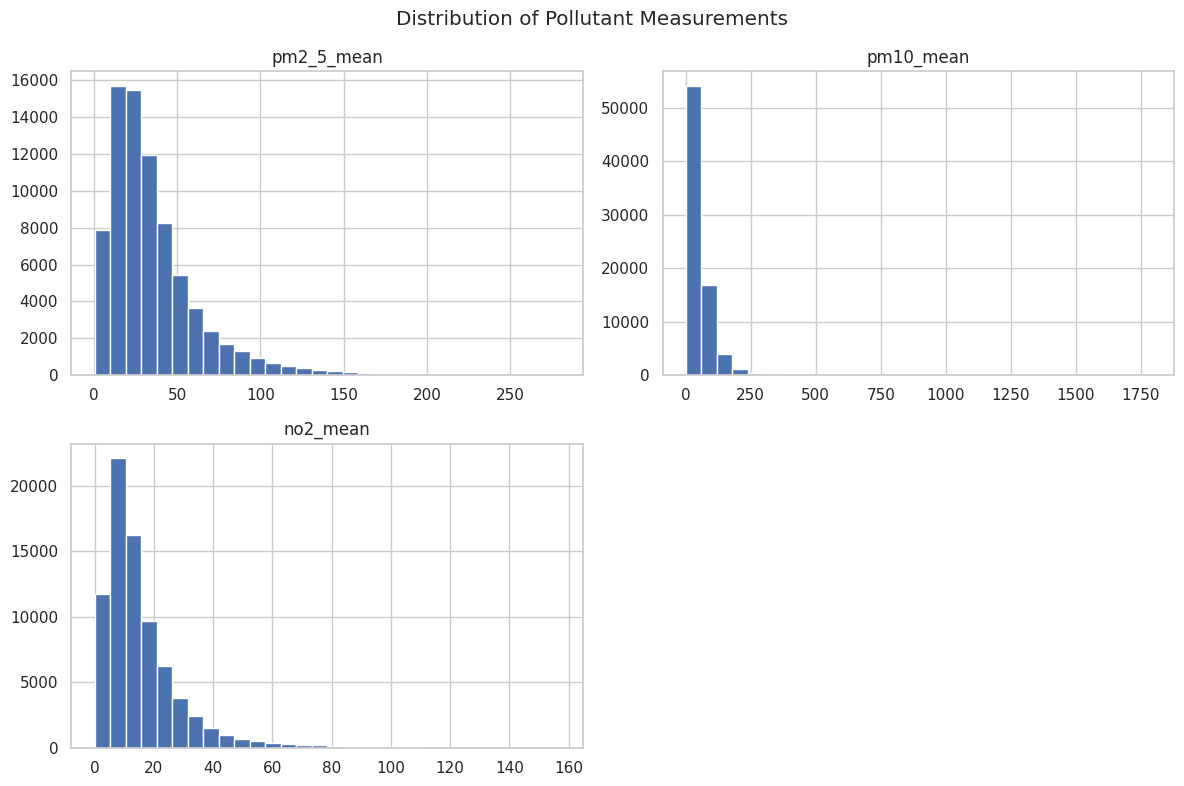

In [ ]:
display(df[available_pollutanats].describe().T)
df[available_pollutanats].hist(figsize=(12,8), bins=30)
plt.suptitle("Distribution of Pollutant Measurements")
plt.tight_layout()
plt.show()


,average_pm25
city,
delhi,74.224278
agra,69.589773
amritsar,65.427430
ludhiana,64.803456
patna,61.178828
lucknow,57.729107
kolkata,57.686822
prayagraj,56.975443
kanpur,56.348479


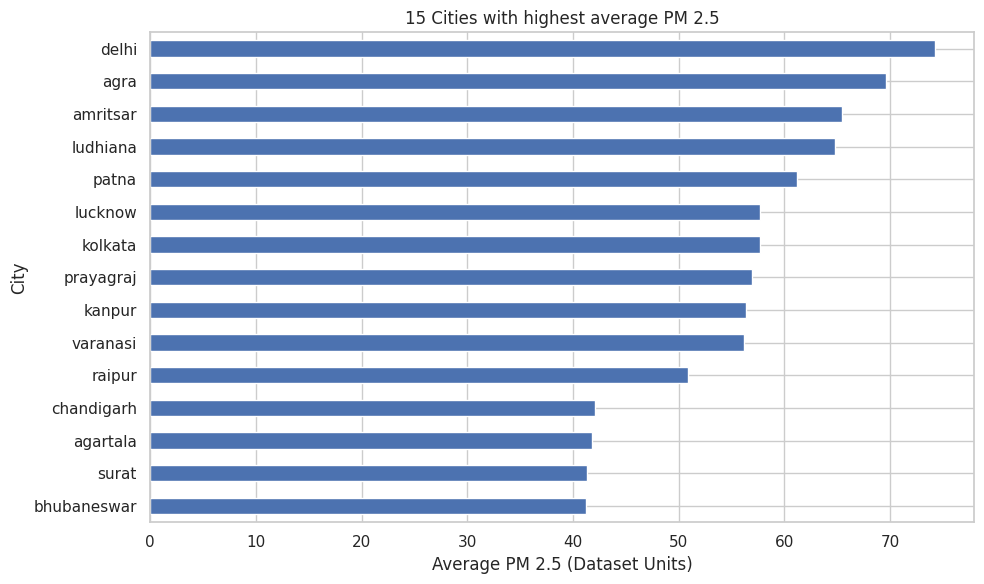

In [ ]:
city_pm25 = df.groupby("city")[pm25_col].mean().dropna().sort_values(ascending=False)
display(city_pm25.head(15).to_frame("average_pm25"))
city_pm25.head(15).sort_values().plot(kind="barh",figsize=(10,6))
plt.title("15 Cities with highest average PM 2.5")
plt.xlabel("Average PM 2.5 (Dataset Units)")
plt.ylabel("City")
plt.tight_layout()
plt.show()

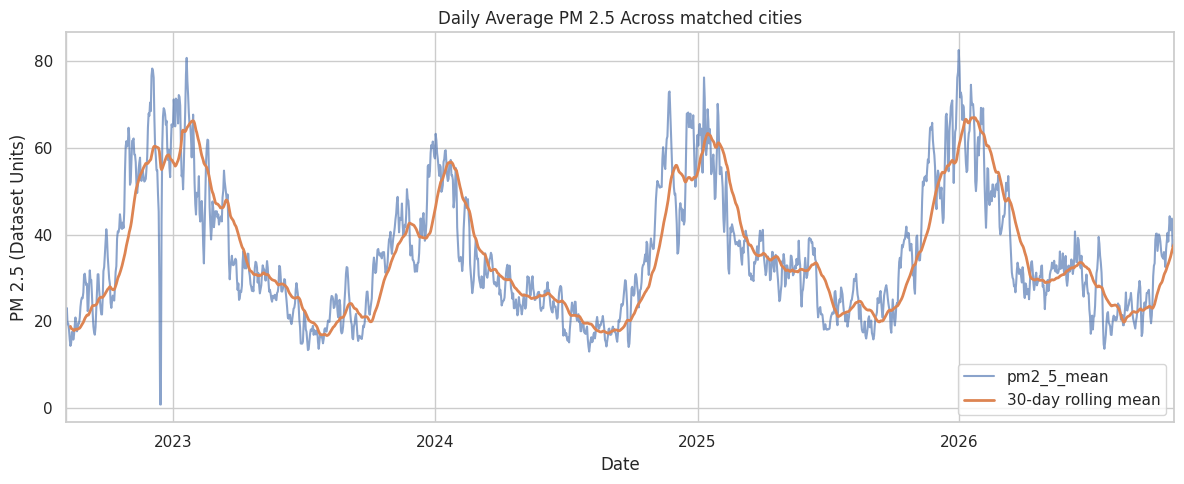

In [ ]:
daily_pm25 = df.groupby("date")[pm25_col].mean().dropna()
daily_pm25.plot(figsize=(12,5),alpha=0.65)
daily_pm25.rolling(30,min_periods=7).mean().plot(figsize=(12,5), linewidth=2,label="30-day rolling mean")
plt.title("Daily Average PM 2.5 Across matched cities")
plt.xlabel("Date")
plt.ylabel("PM 2.5 (Dataset Units)")
plt.legend()
plt.tight_layout()
plt.show()

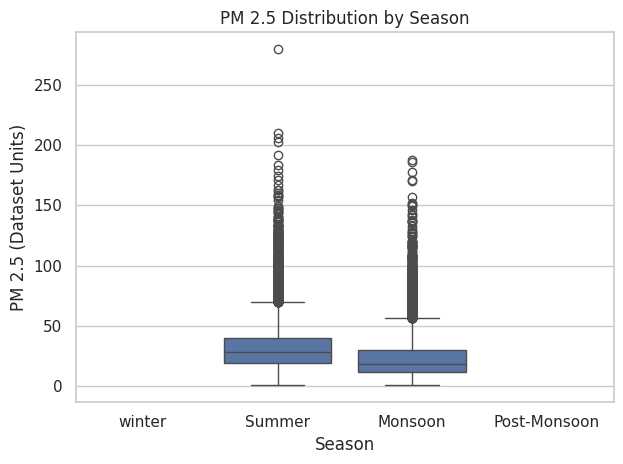

,count,mean,median,std
season,,,,
winter,NaN,NaN,NaN,NaN
Summer,18400.0,31.735521,27.92,18.920810
Monsoon,27250.0,22.717016,18.67,16.258056
Post-Monsoon,NaN,NaN,NaN,NaN


In [ ]:
plot_df = df[["season",pm25_col]].dropna()
order = ["winter","Summer","Monsoon","Post-Monsoon"]
sns.boxplot(data=plot_df,x="season",y=pm25_col,order=order)
plt.title("PM 2.5 Distribution by Season")
plt.xlabel("Season")
plt.ylabel("PM 2.5 (Dataset Units)")
plt.tight_layout()
plt.show()
display(df.groupby("season")[pm25_col].agg(["count","mean","median","std"]).reindex(order))

,pm2_5_mean,temperature_2m_mean,relative_humidity_2m_mean,precipitation_sum
pm2_5_mean,1.000000,-0.171264,-0.092582,-0.224400
temperature_2m_mean,-0.171264,1.000000,-0.076513,0.035383
relative_humidity_2m_mean,-0.092582,-0.076513,1.000000,0.406109
precipitation_sum,-0.224400,0.035383,0.406109,1.000000


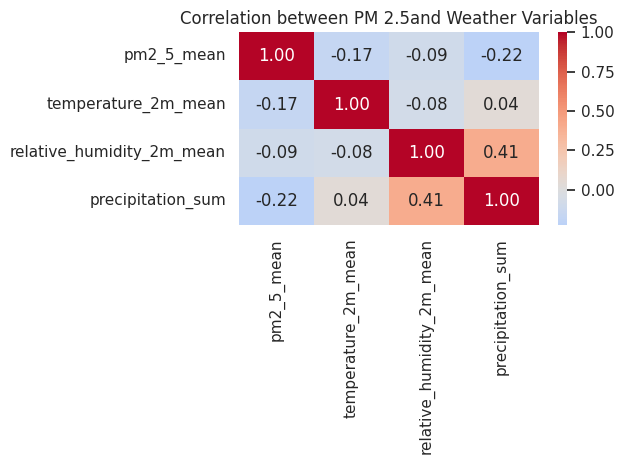

In [ ]:
weather_vars = [c for c in [temp_col,humidity_col,wind_col, rain_col] if c is not None ]

corr_cols =[pm25_col]+ weather_vars
corr = df[corr_cols].corr(numeric_only=True)
display(corr)
sns.heatmap(corr,annot=True,cmap="coolwarm",center=0,fmt=".2f")
plt.title("Correlation between PM 2.5and Weather Variables")
plt.tight_layout()
plt.show()


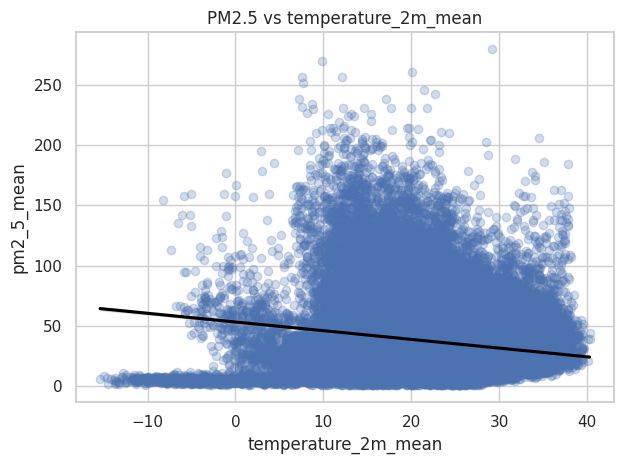

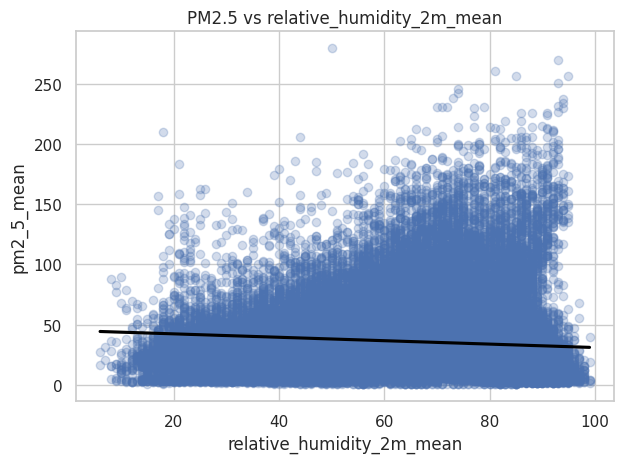

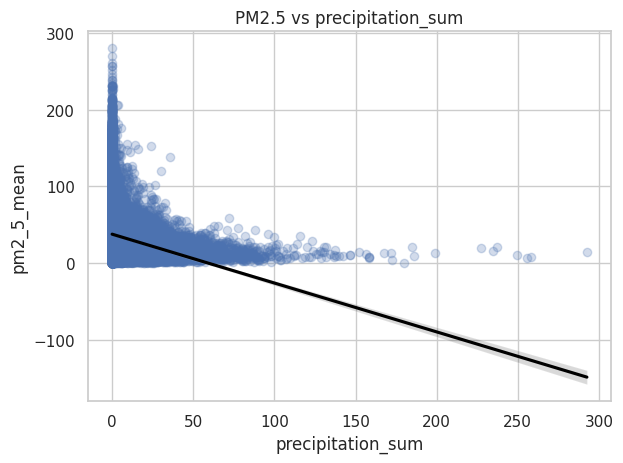

In [ ]:
for weather_col in weather_vars:
  sns.regplot(data=df,x=weather_col,y =pm25_col,scatter_kws={"alpha":0.25},line_kws={"color":"black"})
  plt.title(f"PM2.5 vs {weather_col}")
  plt.tight_layout()
  plt.show()